# Анализ покупок в интернет-магазине

Цель проекта — изучить поведение посетителей и проверить, позволяет ли модель выделить группу с повышенной долей покупок.

Основной вопрос: насколько доля покупателей среди 20% посещений с самым высоким прогнозом превышает среднюю долю на тестовой выборке? В качестве ориентира для учебного проекта выбран lift выше 1,5.

Используется открытый датасет Online Shoppers Purchasing Intention из UCI. Одна запись соответствует посещению интернет-магазина. Анализ относится к завершённым сессиям.

## 1. Загрузка данных

Для анализа используются pandas, NumPy и matplotlib. Основной код подготовки данных и обучения моделей находится в `train.py`.

Целевая переменная `Revenue` показывает, закончилось ли посещение покупкой. На первом этапе проверяются размер таблицы и примеры записей.

In [1]:
from pathlib import Path
import sys

# Редактор может запускать ядро из другой папки.
# Сначала ищем проект рядом с рабочей папкой, затем по исходному пути.
candidates = []
for folder in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([folder, folder / 'shopper-capstone',
                       folder / 'outputs' / 'shopper-capstone'])
candidates.append(Path(r"C:\Users\Gulshat\Documents\Codex\2026-10-14\capstone-data-science-demo-2-1\outputs\shopper-capstone"))
project_dir = next((folder for folder in candidates
                    if (folder / 'train.py').is_file()
                    and (folder / 'data' / 'online_shoppers_intention.csv').is_file()), None)
if project_dir is None:
    raise FileNotFoundError('Откройте всю распакованную папку проекта: рядом с analysis.ipynb нужны train.py и папка data.')
sys.path.insert(0, str(project_dir.resolve()))
print('Папка проекта:', project_dir)

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from train import load_data, run, ROOT
raw, df = load_data()
print("Исходный размер:", raw.shape)
display(raw.head())

Папка проекта: c:\Users\Gulshat\Documents\Codex\2026-10-14\capstone-data-science-demo-2-1\outputs\capstone-project
Исходный размер: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Качество данных

Проверяются типы признаков, пропущенные значения, полные дубли, числовые диапазоны и категории.

В исходных данных 12 330 записей. Пропусков нет. После удаления 125 полных дублей остаётся 12 205 записей. Дубли удаляются до разделения на обучение и тест, чтобы одинаковые записи не попадали в обе выборки.

Необычно большие значения длительности и числа просмотренных страниц не удаляются автоматически: они могут соответствовать реальным посещениям.

In [2]:
print("Дубли:", raw.duplicated().sum())
print("Пропуски:", raw.isna().sum().sum())
display(df.dtypes.to_frame("Тип"))
display(df.describe().round(2))
for col in ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region", "TrafficType"]:
    print(col, df[col].unique())

Дубли: 125
Пропуски: 0


,Тип
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00
mean,2.34,81.65,0.51,34.83,32.05,1206.98,0.02,0.04,5.95,0.06,2.12,2.36,3.15,4.07
std,3.33,177.49,1.28,141.42,44.59,1919.60,0.05,0.05,18.65,0.20,0.91,1.71,2.40,4.02
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00
25%,0.00,0.00,0.00,0.00,8.00,193.00,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00
50%,1.00,9.00,0.00,0.00,18.00,608.94,0.00,0.02,0.00,0.00,2.00,2.00,3.00,2.00
75%,4.00,94.70,0.00,0.00,38.00,1477.15,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00


Month <StringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str
VisitorType <StringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str
Weekend [False  True]
OperatingSystems [1 2 4 3 7 6 8 5]
Browser [ 1  2  3  4  5  6  7 10  8  9 12 13 11]
Region [1 9 2 3 4 5 6 7 8]
TrafficType [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 18 19 16 17 20]


## 3. Распределение целевой переменной

После удаления дублей около 15,6% посещений заканчивается покупкой. Таким образом, классы несбалансированы.

Accuracy недостаточно для оценки: постоянный ответ «покупки нет» даст около 84,4% правильных ответов, но не найдёт ни одного покупателя. Поэтому для сравнения моделей используются average precision, precision, recall и F1, а для оценки выбранной группы — precision top20 и lift.

In [3]:
display(df.Revenue.value_counts().to_frame("Количество"))
print("Доля покупок:", df.Revenue.mean())
df.Revenue.value_counts().rename(index={False:"Без покупки", True:"Покупка"}).plot.bar(title="Количество посещений"); plt.show()

,Количество
Revenue,
False,10297
True,1908


Доля покупок: 0.15632937320770177


C:\Users\Gulshat\AppData\Local\Temp\ipykernel_30756\432843011.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  df.Revenue.value_counts().rename(index={False:"Без покупки", True:"Покупка"}).plot.bar(title="Количество посещений"); plt.show()


## 4. Тип посетителя и месяц

Проверяются два предположения: доля покупок различается между типами посетителей и между месяцами. Для каждой группы рассчитываются доля покупок и число наблюдений.

У новых посетителей доля покупок составляет 24,9%, у вернувшихся — 14,1%. Размеры групп различаются: 1 693 и 10 431 запись соответственно. Группа Other содержит только 81 запись, поэтому её показатели требуют осторожной интерпретации.

В ноябре доля покупок составляет 25,5%, в феврале — 1,7%. Данные охватывают один год, а январь и апрель не представлены. Эти различия описывают выборку и не доказывают устойчивую сезонность или причинное влияние месяца.

In [4]:
for col in ["VisitorType", "Month"]:
    table = df.groupby(col).Revenue.agg(["mean", "count"])
    display(table)
    (table["mean"]*100).plot.bar(title=f"Доля покупок (%): {col}"); plt.show()

,mean,count
VisitorType,,
New_Visitor,0.249262,1693
Other,0.197531,81
Returning_Visitor,0.140926,10431


C:\Users\Gulshat\AppData\Local\Temp\ipykernel_30756\2818665664.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (table["mean"]*100).plot.bar(title=f"Доля покупок (%): {col}"); plt.show()


,mean,count
Month,,
Aug,0.175520,433
Dec,0.126612,1706
Feb,0.016575,181
Jul,0.152778,432
June,0.101754,285
Mar,0.103226,1860
May,0.109643,3329
Nov,0.254863,2982
Oct,0.209472,549


C:\Users\Gulshat\AppData\Local\Temp\ipykernel_30756\2818665664.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (table["mean"]*100).plot.bar(title=f"Доля покупок (%): {col}"); plt.show()


## 5. Просмотр товарных страниц

Для посещений с покупкой и без покупки сравниваются медианы числа товарных страниц и времени на них. Boxplot позволяет оценить различия распределений.

Точки выбросов скрыты только на графике. Соответствующие записи остаются в данных для обучения. Наблюдаемые различия не означают, что увеличение времени на сайте само по себе приводит к покупке.

In [5]:
display(df.groupby("Revenue")[["ProductRelated", "ProductRelated_Duration"]].median())
plt.boxplot([df.loc[~df.Revenue,"ProductRelated"], df.loc[df.Revenue,"ProductRelated"]], tick_labels=["Без покупки", "Покупка"], showfliers=False)
plt.ylabel("Просмотрено товарных страниц"); plt.show()

,ProductRelated,ProductRelated_Duration
Revenue,,
False,16.0,526.00000
True,29.0,1109.90625


C:\Users\Gulshat\AppData\Local\Temp\ipykernel_30756\254673507.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.ylabel("Просмотрено товарных страниц"); plt.show()


## 6. Подготовка признаков и обучение

`Revenue` используется только как целевая переменная. `PageValues` исключён из входных признаков: показатель связан с ценностью страниц относительно транзакций, а момент его расчёта неизвестен. Это решение снижает риск утечки, хотя её наличие в исходных данных не доказано. В модель входят 16 признаков.

Данные разделяются на обучение и тест в пропорции 80/20 с сохранением доли классов и `random_state=42`. Обучающая выборка содержит 9 764 записи, тестовая — 2 441.

Числовые признаки обрабатываются с помощью заполнения медианой и StandardScaler. Категориальные признаки преобразуются через OneHotEncoder. Преобразования входят в Pipeline и обучаются внутри каждого разбиения кросс-валидации.

Сравниваются базовая модель с одинаковой оценкой для всех посещений, логистическая регрессия и случайный лес. GridSearchCV подбирает параметры на трёх частях обучающей выборки. Модель выбирается по средней average precision на кросс-валидации. Финальный тест не участвует в подборе.

In [6]:
metrics, summary = run()
display(metrics.round(3))
print("Выбрана по CV:", summary["winner"])

Training: Logistic regression
Training: Random forest
              Model  CV_PR_AUC  Test_PR_AUC  ROC_AUC  Precision_0.5  Recall_0.5   F1_0.5  Precision_top20  Lift_top20
           Baseline        NaN     0.156493 0.500000       0.000000    0.000000 0.000000         0.156493    1.000000
Logistic regression   0.325854     0.336783 0.756466       0.521739    0.031414 0.059259         0.337423    2.156153
      Random forest   0.375873     0.383944 0.786749       0.500000    0.057592 0.103286         0.374233    2.391369
{
  "raw_rows": 12330,
  "rows": 12205,
  "duplicates_removed": 125,
  "missing_cells": 0,
  "purchase_rate": 0.15632937320770177,
  "train_rows": 9764,
  "test_rows": 2441,
  "test_purchase_rate": 0.15649324047521507,
  "winner": "Random forest",
  "best_parameters": {
    "Logistic regression": {
      "model__C": 0.1
    },
    "Random forest": {
      "model__max_depth": null,
      "model__min_samples_leaf": 3
    }
  },
  "seed": 42,
  "excluded": [
    "Revenue (

,Model,CV_PR_AUC,Test_PR_AUC,ROC_AUC,Precision_0.5,Recall_0.5,F1_0.5,Precision_top20,Lift_top20
0,Baseline,NaN,0.156,0.500,0.000,0.000,0.000,0.156,1.000
1,Logistic regression,0.326,0.337,0.756,0.522,0.031,0.059,0.337,2.156
2,Random forest,0.376,0.384,0.787,0.500,0.058,0.103,0.374,2.391


Выбрана по CV: Random forest


## 7. Результаты и оценка выбранной группы

В этом проекте название PR-AUC используется для average precision. Эта метрика оценивает качество ранжирования с учётом precision и recall и не равна доле правильных ответов.

По кросс-валидации выбран случайный лес: average precision составляет 0,376 против 0,326 у логистической регрессии. На финальном тесте результаты составляют 0,384 и 0,337 соответственно. У базовой модели test average precision равна 0,156.

Precision top20 — доля покупателей среди 20% посещений с самым высоким прогнозом. Lift — отношение этой доли к средней доле покупателей на тесте. Для базовой модели оценки одинаковы, поэтому ожидаемая доля покупок при случайном отборе равна средней.

При пороге 0,5 recall случайного леса составляет лишь 5,8%. Поэтому основное применение модели в проекте — ранжирование посещений, а не поиск всех покупателей при этом пороге.

Отобрано посещений: 489
Найдено покупателей: 183
Доля покупок в группе: 0.37423312883435583
Lift: 2.3913692866090646


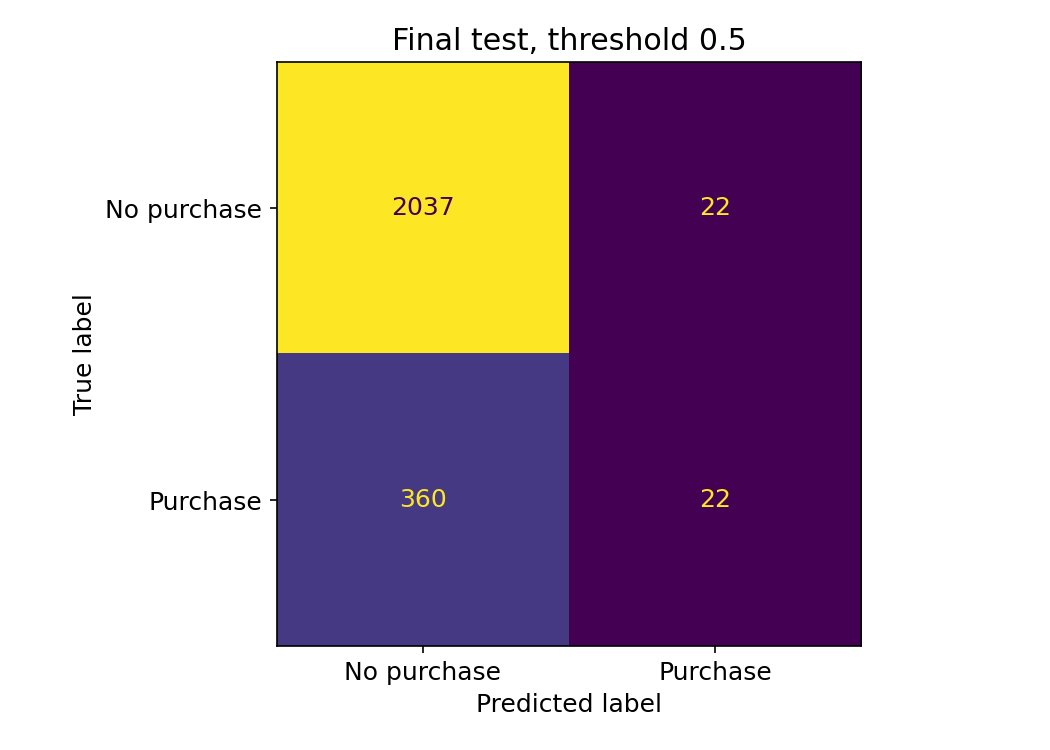

In [7]:
pred = pd.read_csv(ROOT/"results/test_predictions.csv")
k = int(np.ceil(.2*len(pred)))
top = pred.sort_values("score", ascending=False).head(k)
print("Отобрано посещений:", k)
print("Найдено покупателей:", int(top.actual.sum()))
print("Доля покупок в группе:", top.actual.mean())
print("Lift:", top.actual.mean()/pred.actual.mean())
display(Image(filename=str(ROOT/"results/confusion.png")))

## 8. Выводы и ограничения

Случайный лес показал лучшие результаты среди сравниваемых моделей по выбранной метрике кросс-валидации.

В верхние 20% тестовых посещений вошли 489 записей, включая 183 покупки. Доля покупателей в этой группе составляет 37,4% против 15,6% в среднем на тесте. Lift равен 2,39. В выбранной группе находятся 47,9% всех покупателей тестовой выборки. Учебный ориентир lift выше 1,5 достигнут на этом разбиении.

При этом модель имеет низкий recall при пороге 0,5. Результат показывает возможность выделить группу с более высокой долей покупателей, но не доказывает рост продаж или эффективность маркетинговых действий.

Основные ограничения — данные за один год, неизвестный магазин, использование характеристик завершённой сессии и случайное, а не временное разделение. Вероятности отдельно не откалиброваны, доверительные интервалы не рассчитаны.

Для дальнейшего развития нужны данные конкретного магазина, признаки на фиксированный момент до покупки, проверка на будущих периодах и калибровка оценок. Эффект бизнес-действий следует проверять отдельным экспериментом.

Источник данных: [Sakar & Kastro (2018), UCI](https://doi.org/10.24432/C5F88Q). Лицензия CC BY 4.0.